In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"
REPORTS_DIR = PROJECT_ROOT / "reports"

df = pd.read_csv(REPORTS_DIR / "dataset_audit.csv")

print("Total images:", len(df))
print(df["folder"].value_counts())

Total images: 1060
folder
homogeneous      696
imgs             200
inhomogeneous    164
Name: count, dtype: int64


##Class Distribution

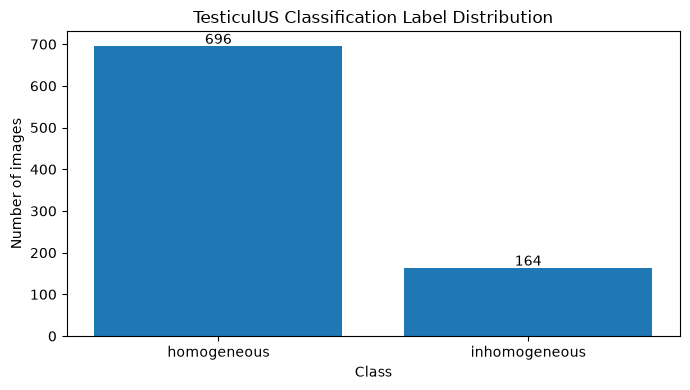

In [2]:
classification_df = df[df["label"].notna()].copy()

class_counts = (
    classification_df["folder"]
    .value_counts()
    .reindex(["homogeneous", "inhomogeneous"])
)

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    class_counts.index,
    class_counts.values
)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        str(int(bar.get_height())),
        ha="center"
    )

ax.set_title("TesticulUS Classification Label Distribution")
ax.set_ylabel("Number of images")
ax.set_xlabel("Class")

plt.tight_layout()
plt.show()

In [4]:
#Image Dimensions

dimension_counts = (
    df.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
)

print(dimension_counts.head(20))

print("\nImage modes:")
print(df["mode"].value_counts())

print("\nIntensity summary:")
print(
    df[["mean_intensity", "std_intensity"]]
    .describe()
)

width  height
300    300       860
1406   943        17
1407   943         9
1406   942         8
1407   942         8
1405   943         6
1408   943         6
       942         6
       941         6
1407   941         5
1405   941         4
       942         3
1406   945         3
       941         2
1407   944         2
1408   944         2
1406   944         2
       728         2
1409   943         2
1584   1179        2
dtype: int64

Image modes:
mode
L      860
RGB    200
Name: count, dtype: int64

Intensity summary:
       mean_intensity  std_intensity
count     1060.000000    1060.000000
mean        50.137438      44.987581
std         17.455938       9.413029
min         14.012222      26.298189
25%         36.588510      36.391969
50%         48.025077      45.300327
75%         61.377869      52.633328
max        123.023944      69.010301


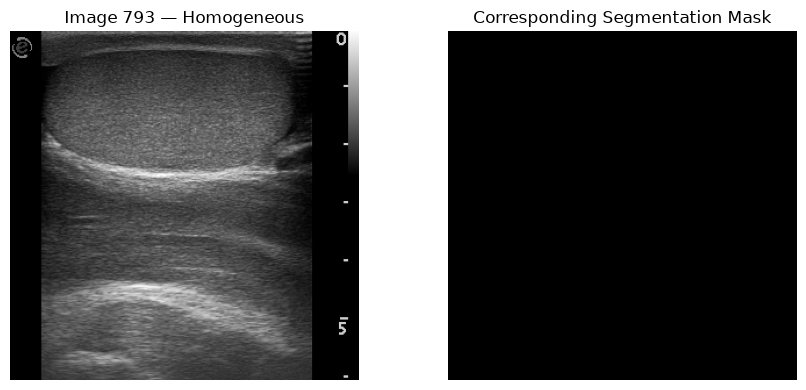

Image shape: (300, 300)
Mask unique values: [0]


In [6]:
# Image 793 inspection 

image_path = DATA_DIR / "homogeneous" / "793.png"
mask_path = DATA_DIR / "masks" / "793.png"

with Image.open(image_path) as img:
    image = np.asarray(img.convert("L"))

with Image.open(mask_path) as msk:
    mask = np.asarray(msk.convert("L"))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Image 793 — Homogeneous")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Corresponding Segmentation Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Image shape:", image.shape)
print("Mask unique values:", np.unique(mask))

### Data-quality finding: Empty segmentation mask

Image 793, labelled as homogeneous, has an entirely empty
segmentation mask despite visible ultrasound anatomy.

The dataset contains 1,059 masks with foreground and background
pixels and one mask containing only background pixels.

This anomaly does not automatically invalidate the image's
classification label. Therefore, image 793 is retained for
full-image classification.

For ROI-based classification, the image will be flagged because
its mask cannot define a foreground region.

The cause of the empty annotation remains unknown.

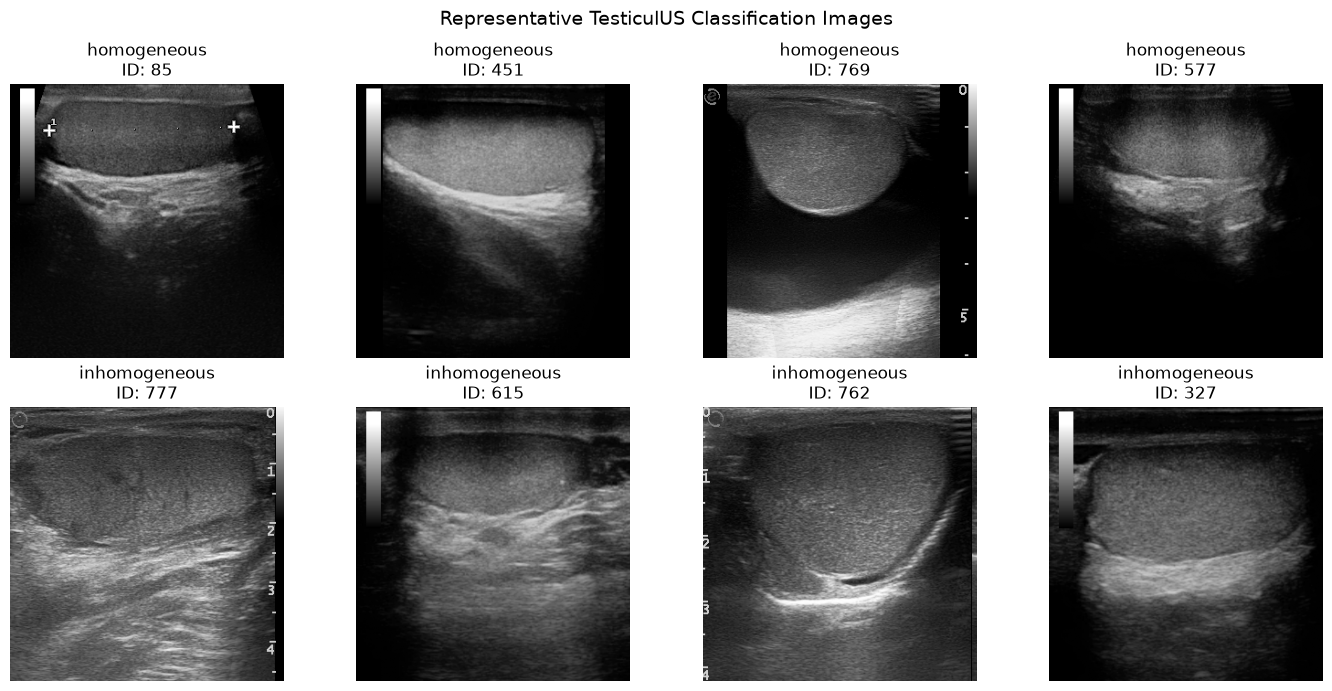

In [7]:
fig, axes = plt.subplots(
    2, 4,
    figsize=(14, 7)
)

classes = ["homogeneous", "inhomogeneous"]

for row, class_name in enumerate(classes):

    samples = (
        df[df["folder"] == class_name]
        .sample(n=4, random_state=42)
    )

    for col, (_, record) in enumerate(samples.iterrows()):

        image_path = PROJECT_ROOT / record["image_path"]

        with Image.open(image_path) as img:
            image = np.asarray(img.convert("L"))

        axes[row, col].imshow(
            image,
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axes[row, col].set_title(
            f"{class_name}\nID: {record['image_id']}"
        )

        axes[row, col].axis("off")

plt.suptitle(
    "Representative TesticulUS Classification Images",
    fontsize=14
)

plt.tight_layout()
plt.show()